# Assignment 4: CIFAR-10 Diffusion

Train a noise-predicting UNet from random initialization for 10 epochs with a learning rate of 0.0001. This notebook includes data preparation, training, evaluation, export, and reload verification.

## 1. Imports and experiment settings

Retain the classroom sinusoidal embedding, residual UNet, offset cosine schedule, noise prediction, reverse diffusion, and EMA decay of 0.8. Use 32 x 32 RGB images and a learning rate of 0.0001 from the first epoch. Ten epochs is an experiment setting, not a guarantee of image quality.

In [1]:
import copy
import json
import math
import random
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split
from torchvision.utils import make_grid, save_image
from tqdm.auto import tqdm

In [2]:
SEED = 42
BATCH_SIZE = 64
IMAGE_SIZE = 32
NUM_CHANNELS = 3
EPOCHS = 10
LEARNING_RATE = 0.0001
SAMPLE_STEPS = 20
RESUME_PATH = None

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

import sys

PROJECT_DIR = None
for folder in (Path.cwd(), *Path.cwd().parents):
    for candidate in (folder, folder / "APAN_5560genai_ass1"):
        if (candidate / "app" / "main.py").is_file():
            PROJECT_DIR = candidate.resolve()
            break
    if PROJECT_DIR is not None:
        break
if PROJECT_DIR is None:
    raise FileNotFoundError("Cannot find the APAN_5560genai_ass1 project near this notebook.")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

DATA_DIR = PROJECT_DIR / "data"
RUN_DIR = PROJECT_DIR.parent / "ASS4" / "outputs" / ("diffusion_from_scratch_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
MODEL_DIR = RUN_DIR / "models"
CHECKPOINT_DIR = RUN_DIR / "checkpoints"
SAMPLE_DIR = RUN_DIR / "samples"
for directory in (MODEL_DIR, CHECKPOINT_DIR, SAMPLE_DIR):
    directory.mkdir(parents=True, exist_ok=True)
print("Device:", device)
print("Run directory:", RUN_DIR)


Device: cuda
Run directory: C:\Users\Milan_Chen\Desktop\SEM3\genai 5560\ASS4\outputs\diffusion_from_scratch_20261118_185249_410982


## 2. Load CIFAR-10

Load pixels in [0, 1]. The model applies normalization internally, so no
Normalize transform is used here. Use 45,000 training images, 5,000 validation
images, and the separate 10,000-image test split. Labels are not used for training.

In [3]:
transform = transforms.ToTensor()
full_train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR, train=True, download=True, transform=transform
)
train_dataset, val_dataset = random_split(
    full_train_dataset, [45000, 5000],
    generator=torch.Generator().manual_seed(SEED)
)
test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR, train=False, download=True, transform=transform
)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print("Train:", len(train_dataset), "Validation:", len(val_dataset), "Test:", len(test_dataset))

Train: 45000 Validation: 5000 Test: 10000


Image batch: torch.Size([64, 3, 32, 32])


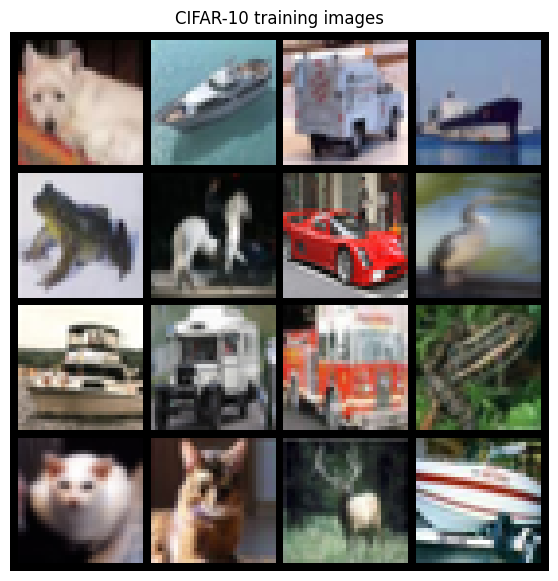

In [4]:
def show_images(images, title, nrow=4):
    grid = make_grid(images.detach().cpu(), nrow=nrow)
    plt.figure(figsize=(7, 7))
    plt.imshow(grid.permute(1, 2, 0))
    plt.title(title)
    plt.axis("off")
    plt.show()

images, labels = next(iter(train_loader))
print("Image batch:", images.shape)
show_images(images[:16], "CIFAR-10 training images")

## 3. Calculate training-set normalization

Estimate one mean and standard deviation per RGB channel using only the training subset.
Accumulate pixel sums and squared sums in batches to avoid making a large float copy
of the dataset. These statistics are saved with the model and restored for inference.

In [5]:
channel_sum = torch.zeros(3, dtype=torch.float64)
channel_square_sum = torch.zeros(3, dtype=torch.float64)
pixel_count = 0
stats_loader = DataLoader(train_dataset, batch_size=256, shuffle=False, num_workers=0)
for batch, _ in tqdm(stats_loader, desc="Training statistics"):
    batch = batch.to(torch.float64)
    channel_sum += batch.sum(dim=(0, 2, 3))
    channel_square_sum += batch.square().sum(dim=(0, 2, 3))
    pixel_count += batch.size(0) * batch.size(2) * batch.size(3)
train_mean = (channel_sum / pixel_count).float()
train_std = (channel_square_sum / pixel_count - train_mean.double().square()).clamp_min(1e-12).sqrt().float()
print("Mean:", train_mean)
print("Standard deviation:", train_std)

Training statistics:   0%|          | 0/176 [00:00<?, ?it/s]

Mean: tensor([0.4917, 0.4823, 0.4467])
Standard deviation: tensor([0.2471, 0.2435, 0.2616])


## 4. Encode the noise level and define the schedule

Encode the noise variance using 16 logarithmically spaced frequencies from 1 to 1,000. Concatenate the sine and cosine values to form a 32-dimensional embedding.  
The offset cosine schedule determines the signal and noise coefficients. Their squared values sum to one, and the signal coefficient remains positive.

In [6]:
class SinusoidalEmbedding(nn.Module):
    def __init__(self, num_frequencies=16):
        super().__init__()
        self.num_frequencies = num_frequencies
        frequencies = torch.exp(
            torch.linspace(math.log(1.0), math.log(1000.0), num_frequencies)
        )
        self.register_buffer(
            "angular_speeds", 2.0 * math.pi * frequencies.view(1, 1, 1, -1)
        )

    def forward(self, x):
        x = x.expand(-1, 1, 1, self.num_frequencies)
        sin_part = torch.sin(self.angular_speeds * x)
        cos_part = torch.cos(self.angular_speeds * x)
        return torch.cat([sin_part, cos_part], dim=-1)


def offset_cosine_diffusion_schedule(diffusion_times, min_signal_rate=0.02,
                                   max_signal_rate=0.95):
    start_angle = math.acos(max_signal_rate)
    end_angle = math.acos(min_signal_rate)
    diffusion_angles = start_angle + diffusion_times * (end_angle - start_angle)
    return torch.sin(diffusion_angles), torch.cos(diffusion_angles)

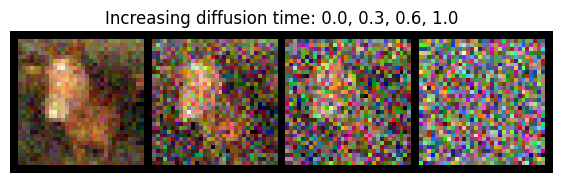

In [7]:
images, _ = next(iter(train_loader))
clean = (images[:1].repeat(4, 1, 1, 1) - train_mean.view(1, 3, 1, 1)) / train_std.view(1, 3, 1, 1)
diffusion_times = torch.tensor([0.0, 0.3, 0.6, 1.0]).view(4, 1, 1, 1)
noise_rates, signal_rates = offset_cosine_diffusion_schedule(diffusion_times)
noisy_images = signal_rates * clean + noise_rates * torch.randn_like(clean)
display_images = (noisy_images * train_std.view(1, 3, 1, 1) + train_mean.view(1, 3, 1, 1)).clamp(0, 1)
show_images(display_images, "Increasing diffusion time: 0.0, 0.3, 0.6, 1.0")

## 5. Build the residual UNet

Down blocks use average pooling; up blocks use bilinear interpolation and skip connections. The final convolution predicts three noise channels.

In [8]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        if in_channels != out_channels:
            self.proj = nn.Conv2d(in_channels, out_channels, kernel_size=1)
        else:
            self.proj = nn.Identity()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1)

    def swish(self, x):
        return x * torch.sigmoid(x)

    def forward(self, x):
        residual = self.proj(x)
        x = self.swish(self.conv1(x))
        x = self.conv2(x)
        return x + residual


class DownBlock(nn.Module):
    def __init__(self, width, block_depth, in_channels):
        super().__init__()
        self.blocks = nn.ModuleList()
        for _ in range(block_depth):
            self.blocks.append(ResidualBlock(in_channels, width))
            in_channels = width
        self.pool = nn.AvgPool2d(kernel_size=2)

    def forward(self, x, skips):
        for block in self.blocks:
            x = block(x)
            skips.append(x)
        return self.pool(x)


class UpBlock(nn.Module):
    def __init__(self, width, block_depth, in_channels):
        super().__init__()
        self.blocks = nn.ModuleList()
        for _ in range(block_depth):
            self.blocks.append(ResidualBlock(in_channels + width, width))
            in_channels = width

    def forward(self, x, skips):
        x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        for block in self.blocks:
            skip = skips.pop()
            x = torch.cat([x, skip], dim=1)
            x = block(x)
        return x

In [9]:
class UNet(nn.Module):
    def __init__(self, image_size, num_channels, embedding_dim=32):
        super().__init__()
        if image_size % 8 != 0 or embedding_dim % 2 != 0:
            raise ValueError("image_size must be divisible by 8 and embedding_dim must be even.")
        self.initial = nn.Conv2d(num_channels, 32, kernel_size=1)
        self.num_channels = num_channels
        self.image_size = image_size
        self.embedding_dim = embedding_dim
        self.embedding = SinusoidalEmbedding(num_frequencies=embedding_dim // 2)
        self.down1 = DownBlock(32, in_channels=32 + embedding_dim, block_depth=2)
        self.down2 = DownBlock(64, in_channels=32, block_depth=2)
        self.down3 = DownBlock(96, in_channels=64, block_depth=2)
        self.mid1 = ResidualBlock(96, 128)
        self.mid2 = ResidualBlock(128, 128)
        self.up1 = UpBlock(96, in_channels=128, block_depth=2)
        self.up2 = UpBlock(64, in_channels=96, block_depth=2)
        self.up3 = UpBlock(32, in_channels=64, block_depth=2)
        self.final = nn.Conv2d(32, num_channels, kernel_size=1)
        nn.init.zeros_(self.final.weight)

    def forward(self, noisy_images, noise_variances):
        skips = []
        x = self.initial(noisy_images)
        noise_emb = self.embedding(noise_variances)
        noise_emb = F.interpolate(
            noise_emb.permute(0, 3, 1, 2),
            size=(self.image_size, self.image_size), mode="nearest"
        )
        x = torch.cat([x, noise_emb], dim=1)
        x = self.down1(x, skips)
        x = self.down2(x, skips)
        x = self.down3(x, skips)
        x = self.mid1(x)
        x = self.mid2(x)
        x = self.up1(x, skips)
        x = self.up2(x, skips)
        x = self.up3(x, skips)
        return self.final(x)

## 6. Train noise prediction and generate images

Form a noisy image as signal_rate * image + noise_rate * noise.
Minimize mean squared error between predicted and sampled noise.
After each update, move EMA weights 20% toward the updated network weights.
Generation uses the EMA network and the classroom iterative reverse process.
Normalization statistics are registered buffers so they move with the model.

In [10]:
class DiffusionModel(nn.Module):
    def __init__(self, model, schedule_fn):
        super().__init__()
        self.network = model
        self.ema_network = copy.deepcopy(model)
        self.ema_network.requires_grad_(False)
        self.ema_network.eval()
        self.ema_decay = 0.8
        self.schedule_fn = schedule_fn
        self.register_buffer("normalizer_mean", torch.zeros(1, model.num_channels, 1, 1))
        self.register_buffer("normalizer_std", torch.ones(1, model.num_channels, 1, 1))

    def set_normalizer(self, mean, std):
        device = self.normalizer_mean.device
        mean = torch.as_tensor(mean, dtype=torch.float32, device=device).reshape(1, -1, 1, 1)
        std = torch.as_tensor(std, dtype=torch.float32, device=device).reshape(1, -1, 1, 1)
        if not torch.isfinite(mean).all() or not torch.isfinite(std).all() or (std <= 0).any():
            raise ValueError("Normalization requires finite means and positive standard deviations.")
        self.normalizer_mean.copy_(mean)
        self.normalizer_std.copy_(std)

    def denormalize(self, x):
        return (x * self.normalizer_std + self.normalizer_mean).clamp(0.0, 1.0)

    def denoise(self, noisy_images, noise_rates, signal_rates, training):
        if training:
            network = self.network
            network.train()
        else:
            network = self.ema_network
            network.eval()
        pred_noises = network(noisy_images, noise_rates.square())
        pred_images = (noisy_images - noise_rates * pred_noises) / signal_rates
        return pred_noises, pred_images

    def reverse_diffusion(self, initial_noise, diffusion_steps):
        if diffusion_steps < 1:
            raise ValueError("diffusion_steps must be positive.")
        step_size = 1.0 / diffusion_steps
        current_images = initial_noise
        for step in range(diffusion_steps):
            t = torch.full(
                (initial_noise.size(0), 1, 1, 1), 1 - step * step_size,
                device=initial_noise.device
            )
            noise_rates, signal_rates = self.schedule_fn(t)
            pred_noises, pred_images = self.denoise(
                current_images, noise_rates, signal_rates, training=False
            )
            next_noise_rates, next_signal_rates = self.schedule_fn((t - step_size).clamp(0, 1))
            current_images = next_signal_rates * pred_images + next_noise_rates * pred_noises
        return pred_images

    def generate(self, num_images, diffusion_steps, initial_noise=None):
        if initial_noise is None:
            initial_noise = torch.randn(
                num_images, self.network.num_channels,
                self.network.image_size, self.network.image_size,
                device=self.normalizer_mean.device
            )
        with torch.no_grad():
            return self.denormalize(self.reverse_diffusion(initial_noise, diffusion_steps))

    def train_step(self, images, optimizer, loss_fn):
        images = (images - self.normalizer_mean) / self.normalizer_std
        noises = torch.randn_like(images)
        diffusion_times = torch.rand((images.size(0), 1, 1, 1), device=images.device)
        noise_rates, signal_rates = self.schedule_fn(diffusion_times)
        noisy_images = signal_rates * images + noise_rates * noises
        pred_noises, _ = self.denoise(noisy_images, noise_rates, signal_rates, training=True)
        loss = loss_fn(pred_noises, noises)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        with torch.no_grad():
            for ema_param, param in zip(self.ema_network.parameters(), self.network.parameters()):
                ema_param.copy_(self.ema_decay * ema_param + (1 - self.ema_decay) * param)
        return loss.item()

    def test_step(self, images, loss_fn):
        with torch.no_grad():
            images = (images - self.normalizer_mean) / self.normalizer_std
            noises = torch.randn_like(images)
            diffusion_times = torch.rand((images.size(0), 1, 1, 1), device=images.device)
            noise_rates, signal_rates = self.schedule_fn(diffusion_times)
            noisy_images = signal_rates * images + noise_rates * noises
            pred_noises, _ = self.denoise(noisy_images, noise_rates, signal_rates, training=False)
            loss = loss_fn(pred_noises, noises)
        return loss.item()

## 7. Initialize a new experiment

Create new network and EMA weights, a new Adam optimizer, and fixed initial noise for sample comparisons. No previous weights or training history are loaded. The optimizer uses 0.0001 from epoch 1.

In [11]:
network = UNet(IMAGE_SIZE, NUM_CHANNELS)
diffusion_model = DiffusionModel(network, offset_cosine_diffusion_schedule).to(device)
diffusion_model.set_normalizer(train_mean, train_std)
optimizer = optim.Adam(diffusion_model.network.parameters(), lr=LEARNING_RATE)
loss_fn = nn.MSELoss()
fixed_noise = torch.randn(16, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
start_epoch = 0
history = []
best_val_loss = float("inf")

with torch.no_grad():
    prediction = network(images[:2].to(device), torch.full((2, 1, 1, 1), 0.5, device=device))
print("Noise prediction shape:", prediction.shape)
print("Completed epochs:", start_epoch)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Next epoch:", start_epoch + 1)


Noise prediction shape: torch.Size([2, 3, 32, 32])
Completed epochs: 0
Learning rate: 0.0001
Next epoch: 1


## 8. Train and save checkpoints

Save diffusion_latest.pth with model and optimizer states for possible future continuation and diffusion_best.pth for the lowest
observed validation noise MSE. Save fixed-noise sample grids and history.json
every epoch. Validation uses fresh random noise and times, so its loss is stochastic.
Lower noise MSE alone does not prove better perceptual image quality.

In [12]:
def train_diffusion(model, train_loader, val_loader, optimizer, loss_fn, epochs,
                    checkpoint_dir, sample_dir, fixed_noise, sample_steps,
                    start_epoch=0, history=None, best_val_loss=float("inf")):
    history = [] if history is None else history
    device = next(model.parameters()).device
    for epoch in range(start_epoch, epochs):
        train_total = 0.0
        train_count = 0
        progress = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{epochs} [Train]")
        for images, _ in progress:
            loss = model.train_step(images.to(device), optimizer, loss_fn)
            train_total += loss * images.size(0)
            train_count += images.size(0)
            progress.set_postfix(loss=f"{loss:.4f}")
        val_total = 0.0
        val_count = 0
        for images, _ in tqdm(val_loader, desc="Validation"):
            loss = model.test_step(images.to(device), loss_fn)
            val_total += loss * images.size(0)
            val_count += images.size(0)
        train_loss = train_total / train_count
        val_loss = val_total / val_count
        is_best = val_loss < best_val_loss
        best_val_loss = min(best_val_loss, val_loss)
        record = {"epoch": epoch + 1, "train_loss": train_loss, "val_loss": val_loss}
        history.append(record)
        samples = model.generate(len(fixed_noise), sample_steps, fixed_noise)
        save_image(samples, sample_dir / f"epoch_{epoch + 1:03d}.png", nrow=4)
        checkpoint = {
            "epoch": epoch + 1,
            "model_state_dict": model.network.state_dict(),
            "ema_model_state_dict": model.ema_network.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "normalizer_mean": model.normalizer_mean.cpu(),
            "normalizer_std": model.normalizer_std.cpu(),
            "ema_decay": model.ema_decay,
            "fixed_noise": fixed_noise.cpu(),
            "history": history,
            "best_val_loss": best_val_loss,
            "image_size": model.network.image_size,
            "num_channels": model.network.num_channels,
        }
        torch.save(checkpoint, checkpoint_dir / "diffusion_latest.pth")
        if is_best:
            torch.save(checkpoint, checkpoint_dir / "diffusion_best.pth")
        (checkpoint_dir.parent / "history.json").write_text(json.dumps(history, indent=2))
        print(record)
        show_images(samples, f"Diffusion model: epoch {epoch + 1}")
    return history

Epoch 1/10 [Train]:   0%|          | 0/704 [00:00<?, ?it/s]

Validation:   0%|          | 0/79 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.24445186519092985, 'val_loss': 0.09165665512084961}


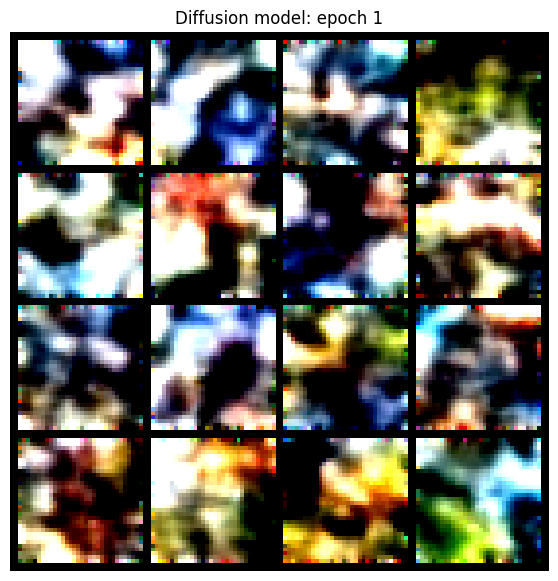

Epoch 2/10 [Train]:   0%|          | 0/704 [00:00<?, ?it/s]

Validation:   0%|          | 0/79 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 0.08477368317047755, 'val_loss': 0.07665187343358994}


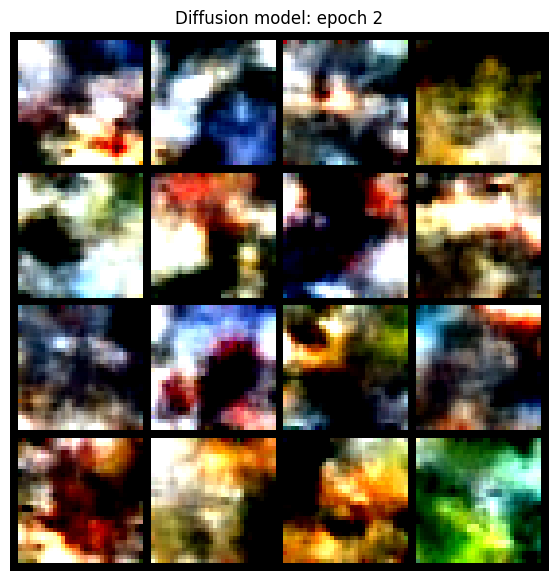

Epoch 3/10 [Train]:   0%|          | 0/704 [00:00<?, ?it/s]

Validation:   0%|          | 0/79 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 0.0745747101565202, 'val_loss': 0.07113890035152436}


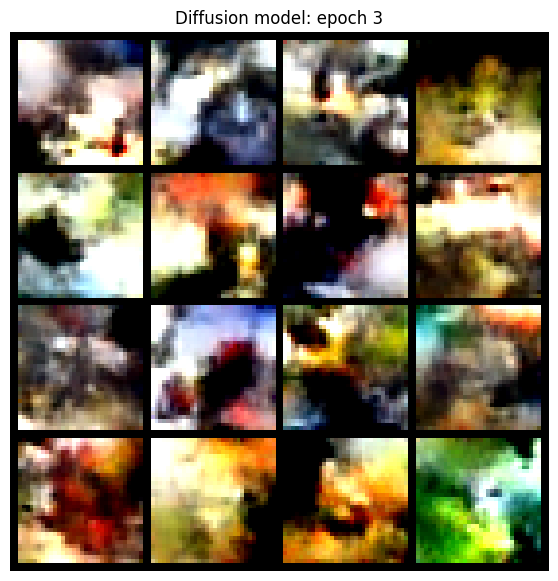

Epoch 4/10 [Train]:   0%|          | 0/704 [00:00<?, ?it/s]

Validation:   0%|          | 0/79 [00:00<?, ?it/s]

{'epoch': 4, 'train_loss': 0.0696299859099918, 'val_loss': 0.068441011095047}


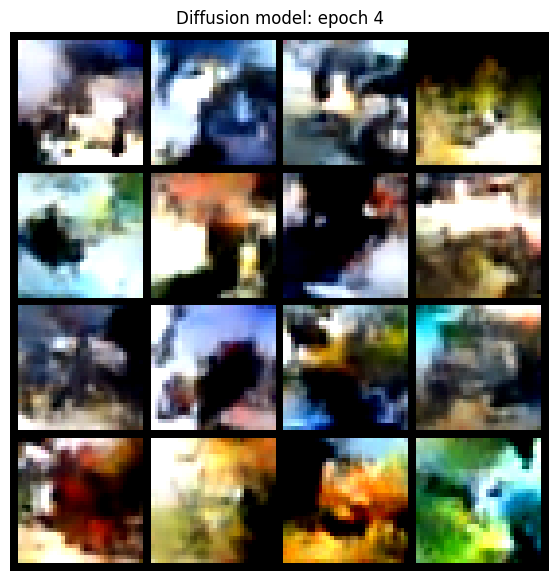

Epoch 5/10 [Train]:   0%|          | 0/704 [00:00<?, ?it/s]

Validation:   0%|          | 0/79 [00:00<?, ?it/s]

{'epoch': 5, 'train_loss': 0.06646821027729247, 'val_loss': 0.06567980877757072}


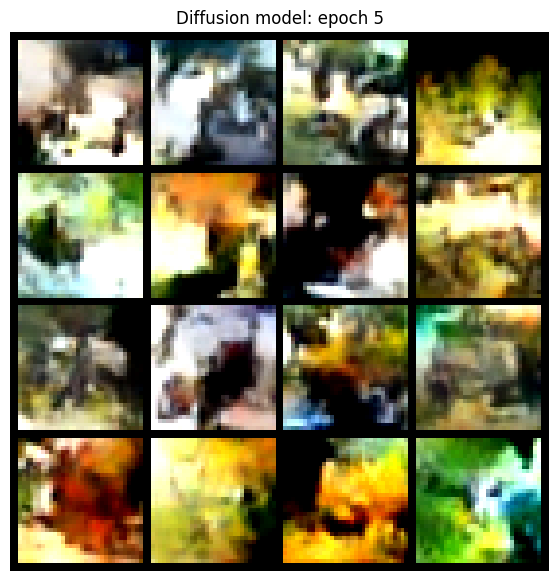

Epoch 6/10 [Train]:   0%|          | 0/704 [00:00<?, ?it/s]

Validation:   0%|          | 0/79 [00:00<?, ?it/s]

{'epoch': 6, 'train_loss': 0.0645859010166592, 'val_loss': 0.06380141517519951}


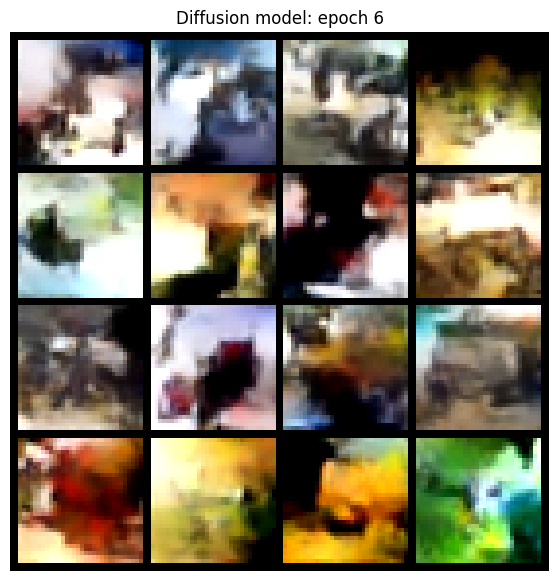

Epoch 7/10 [Train]:   0%|          | 0/704 [00:00<?, ?it/s]

Validation:   0%|          | 0/79 [00:00<?, ?it/s]

{'epoch': 7, 'train_loss': 0.06354683477414978, 'val_loss': 0.06347881460189819}


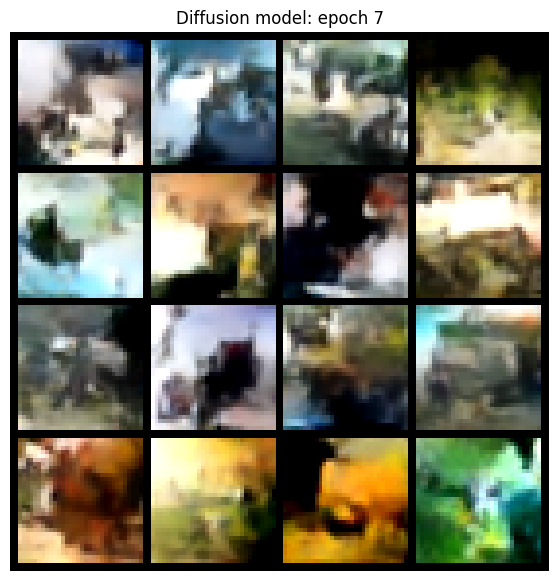

Epoch 8/10 [Train]:   0%|          | 0/704 [00:00<?, ?it/s]

Validation:   0%|          | 0/79 [00:00<?, ?it/s]

{'epoch': 8, 'train_loss': 0.062083550763130185, 'val_loss': 0.062041350823640824}


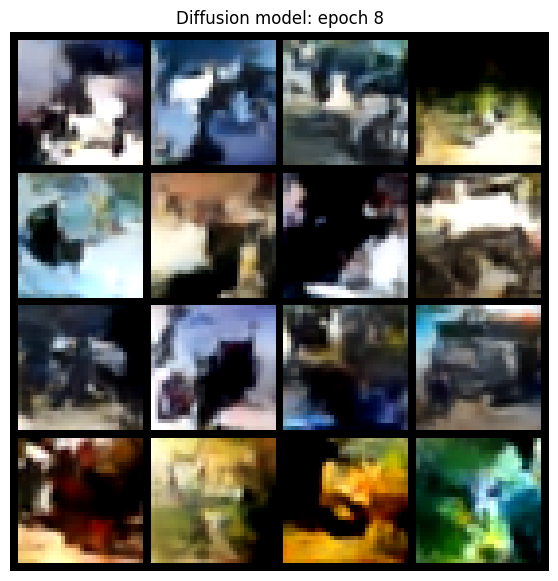

Epoch 9/10 [Train]:   0%|          | 0/704 [00:00<?, ?it/s]

Validation:   0%|          | 0/79 [00:00<?, ?it/s]

{'epoch': 9, 'train_loss': 0.061541966344250576, 'val_loss': 0.062478676974773405}


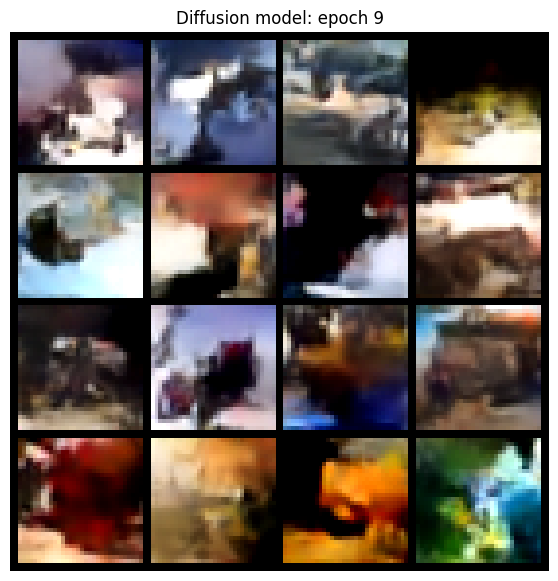

Epoch 10/10 [Train]:   0%|          | 0/704 [00:00<?, ?it/s]

Validation:   0%|          | 0/79 [00:00<?, ?it/s]

{'epoch': 10, 'train_loss': 0.06053903405268987, 'val_loss': 0.05951071040630341}


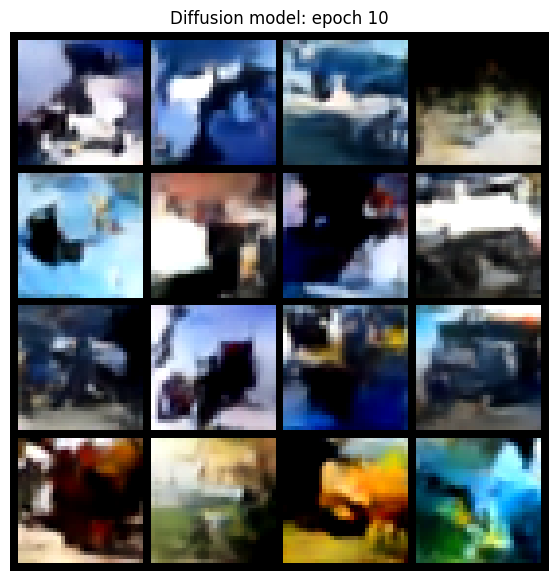

In [13]:
history = train_diffusion(
    diffusion_model, train_loader, val_loader, optimizer, loss_fn, EPOCHS,
    CHECKPOINT_DIR, SAMPLE_DIR, fixed_noise, SAMPLE_STEPS,
    start_epoch=start_epoch, history=history, best_val_loss=best_val_loss
)

## 9. Review learning curves

Training loss uses the main network; validation loss uses EMA weights.
Inspect sample grids alongside both curves and report remaining visual limitations.

Training remained numerically stable over 10 epochs with a learning rate of 0.0001. Validation noise MSE decreased from 0.09166 to 0.05951, and epoch 10 was selected as the best checkpoint. Its test noise MSE was 0.05971.

The generated samples show coherent color regions and coarse spatial structure, but most objects remain difficult to identify. Lower noise MSE indicates improved noise prediction, but does not by itself establish realistic image generation.

In the inspected samples, Diffusion produced more coherent spatial structure than the Energy model, whose outputs were dominated by colored textures and grid-like patterns. This is a qualitative comparison under the tested settings, rather than a general ranking of the two methods.

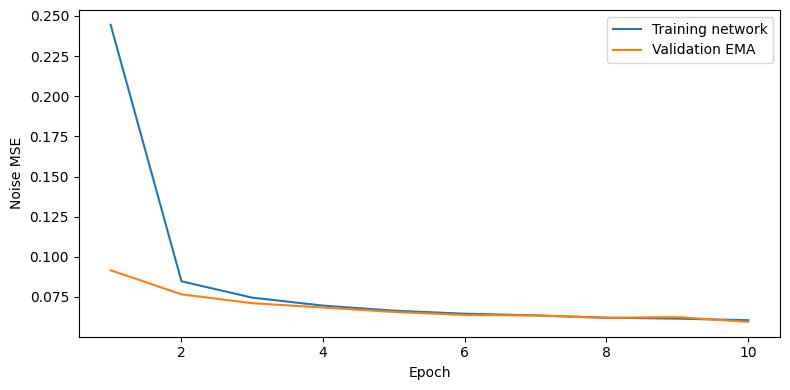

In [14]:
epochs = [row["epoch"] for row in history]
plt.figure(figsize=(8, 4))
plt.plot(epochs, [row["train_loss"] for row in history], label="Training network")
plt.plot(epochs, [row["val_loss"] for row in history], label="Validation EMA")
plt.xlabel("Epoch")
plt.ylabel("Noise MSE")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Compare sampling steps

Compare 20, 50, and 100 reverse-diffusion steps with the same final-epoch EMA weights and four identical initial noise tensors. Each column starts from the same noise; the discretization changes with the step count. No training is performed. More steps do not guarantee better visual quality.

Compared checkpoint epoch: 10


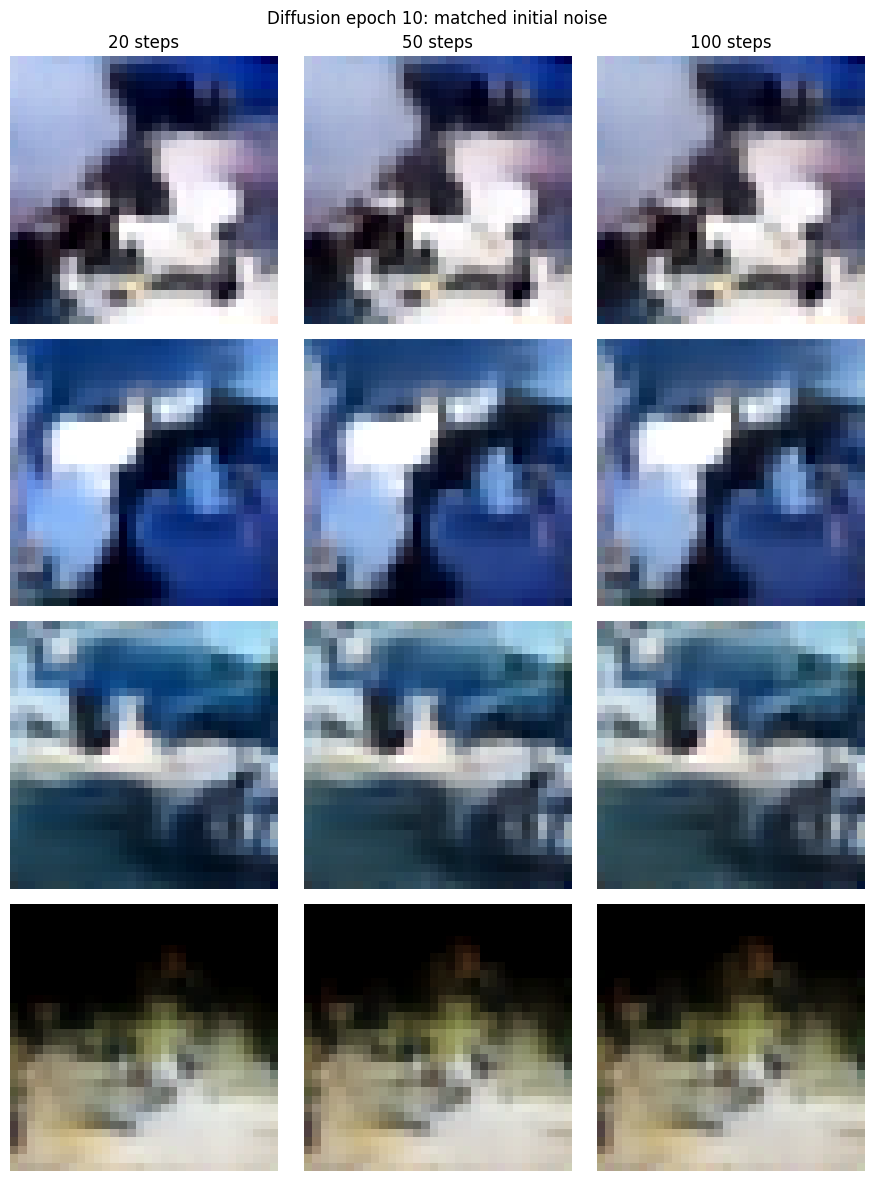

In [17]:
comparison_checkpoint = torch.load(CHECKPOINT_DIR / "diffusion_latest.pth", map_location="cpu", weights_only=True)
comparison_model = DiffusionModel(UNet(IMAGE_SIZE, NUM_CHANNELS), offset_cosine_diffusion_schedule).to(device)
comparison_model.ema_network.load_state_dict(comparison_checkpoint["ema_model_state_dict"])
comparison_model.set_normalizer(comparison_checkpoint["normalizer_mean"], comparison_checkpoint["normalizer_std"])
comparison_model.eval()
comparison_noise = comparison_checkpoint["fixed_noise"][:4].to(device)
fig, axes = plt.subplots(4, 3, figsize=(9, 12))
for column, steps in enumerate([20, 50, 100]):
    comparison_samples = comparison_model.generate(4, steps, comparison_noise.clone()).cpu()
    if not torch.isfinite(comparison_samples).all():
        raise RuntimeError("Non-finite samples in sampling comparison.")
    for row in range(4):
        axes[row, column].imshow(comparison_samples[row].permute(1, 2, 0))
        axes[row, column].axis("off")
        if row == 0:
            axes[row, column].set_title(f"{steps} steps")
fig.suptitle(f"Diffusion epoch {comparison_checkpoint['epoch']}: matched initial noise")
plt.tight_layout()
plt.savefig(SAMPLE_DIR / "sampling_steps_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Compared checkpoint epoch:", comparison_checkpoint["epoch"])
del comparison_model


For the four inspected initial noise tensors at epoch 10, increasing sampling from 20 to 50 or 100 steps changed local colors and edges but did not yield a clear improvement in object recognizability. The overall layouts remained similar. This small qualitative comparison does not establish that additional steps are ineffective for all samples.

## 11. Evaluate and export the selected model

Select the checkpoint with the lowest validation noise MSE and evaluate it once on the held-out test set. Save its EMA weights and normalization statistics in this run's models folder. The export is kept in the experiment directory; Section 13 copies the selected export into the API model directory. Noise MSE alone does not establish perceptual image quality.

In [15]:
checkpoint = torch.load(CHECKPOINT_DIR / "diffusion_best.pth", map_location=device, weights_only=True)
diffusion_model.network.load_state_dict(checkpoint["model_state_dict"])
diffusion_model.ema_network.load_state_dict(checkpoint["ema_model_state_dict"])
diffusion_model.set_normalizer(checkpoint["normalizer_mean"], checkpoint["normalizer_std"])
test_total = 0.0
test_count = 0
for images, _ in tqdm(test_loader, desc="Test noise MSE"):
    loss = diffusion_model.test_step(images.to(device), loss_fn)
    test_total += loss * images.size(0)
    test_count += images.size(0)
print("Selected epoch:", checkpoint["epoch"])
print("Test noise MSE:", test_total / test_count)

checkpoint = torch.load(CHECKPOINT_DIR / "diffusion_best.pth", map_location="cpu", weights_only=True)
export = {name: checkpoint[name] for name in (
    "ema_model_state_dict", "normalizer_mean", "normalizer_std", "image_size", "num_channels", "epoch"
)}
export_path = MODEL_DIR / "cifar10_diffusion.pth"
torch.save(export, export_path)
print("Exported:", export_path)

Test noise MSE:   0%|          | 0/157 [00:00<?, ?it/s]

Selected epoch: 10
Test noise MSE: 0.05971338505744934
Exported: C:\Users\Milan_Chen\Desktop\SEM3\genai 5560\ASS4\outputs\diffusion_from_scratch_20261118_185249_410982\models\cifar10_diffusion.pth


## 12. Verify the exported model and generate fresh samples

Reload the exported model and verify that its predictions and normalization statistics match the original model. Then generate new samples.

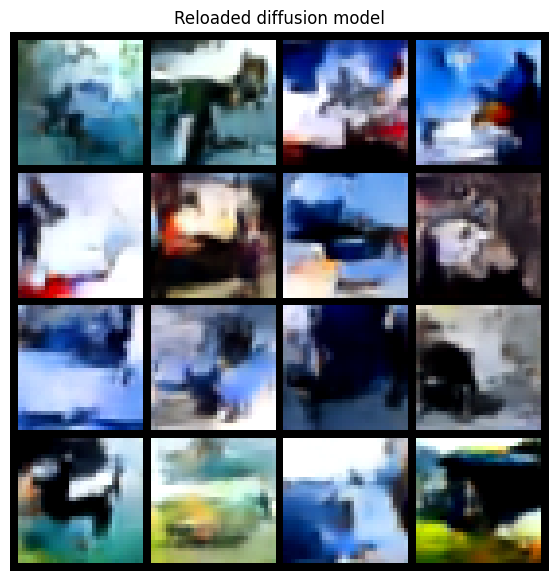

Reload verification passed.


In [16]:
from helper_lib.diffusion import DiffusionModel as APIDiffusionModel
from helper_lib.diffusion import UNet as APIUNet
from helper_lib.diffusion import offset_cosine_diffusion_schedule as api_schedule

export = torch.load(export_path, map_location="cpu", weights_only=True)
reloaded_model = APIDiffusionModel(APIUNet(IMAGE_SIZE, NUM_CHANNELS), api_schedule)
reloaded_model.ema_network.load_state_dict(export["ema_model_state_dict"])
reloaded_model.set_normalizer(export["normalizer_mean"], export["normalizer_std"])
reloaded_model.eval()
reference_network = copy.deepcopy(diffusion_model.ema_network).cpu().eval()
probe = fixed_noise[:2].cpu()
variance = torch.full((2, 1, 1, 1), 0.5)

with torch.no_grad():
    expected = reference_network(probe, variance)
    actual = reloaded_model.ema_network(probe, variance)
torch.testing.assert_close(actual, expected, rtol=1e-4, atol=1e-5)
torch.testing.assert_close(reloaded_model.normalizer_mean, diffusion_model.normalizer_mean.cpu())
torch.testing.assert_close(reloaded_model.normalizer_std, diffusion_model.normalizer_std.cpu())
samples = reloaded_model.generate(16, SAMPLE_STEPS)
save_image(samples, SAMPLE_DIR / "final_samples.png", nrow=4)
show_images(samples, "Reloaded diffusion model")
print("Reload verification passed.")


## 13. Install the selected export for FastAPI

Copy the selected export into the project models/cifar10_diffusion.pth file used by /generate-diffusion. For this completed experiment, the selected checkpoint is epoch 10. Preserve a timestamped backup if an API model file already exists. Verify the model metadata and call the same image-generation service used by the API. This updates the local API model file; it does not publish or deploy a remote service.

In [18]:
import shutil
from io import BytesIO
from PIL import Image
from app import diffusion_service

api_model_path = PROJECT_DIR / "models" / "cifar10_diffusion.pth"
api_model_path.parent.mkdir(parents=True, exist_ok=True)
if api_model_path.exists():
    backup_path = RUN_DIR / ("api_diffusion_before_update_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f") + ".pth")
    shutil.copy2(api_model_path, backup_path)
    print("Previous API weights saved:", backup_path)
shutil.copy2(export_path, api_model_path)
api_export = torch.load(api_model_path, map_location="cpu", weights_only=True)
assert api_export["epoch"] == export["epoch"]
for name, value in export["ema_model_state_dict"].items():
    torch.testing.assert_close(api_export["ema_model_state_dict"][name], value, rtol=0, atol=0)
diffusion_service.load_model.cache_clear()
image_bytes = diffusion_service.generate_diffusion_images(num_samples=4, steps=20)
api_image = Image.open(BytesIO(image_bytes))
assert api_image.format == "PNG"
api_image.load()
api_sample_path = SAMPLE_DIR / "api_diffusion_service.png"
api_sample_path.write_bytes(image_bytes)
print("API model:", api_model_path)
print("API model epoch:", api_export["epoch"])
print("API service output:", api_image.format, api_image.size)
print("Saved:", api_sample_path)


API model: C:\Users\Milan_Chen\Desktop\SEM3\genai 5560\APAN_5560genai_ass1\models\cifar10_diffusion.pth
API model epoch: 10
API service output: PNG (138, 36)
Saved: C:\Users\Milan_Chen\Desktop\SEM3\genai 5560\ASS4\outputs\diffusion_from_scratch_20261118_185249_410982\samples\api_diffusion_service.png


### Start and call the API

From the project repository root, run `uv run fastapi dev app/main.py`, then open `http://127.0.0.1:8000/generate-diffusion?num_samples=4&steps=20`. The endpoint returns a PNG grid. It accepts 1–16 samples and 1–200 sampling steps; invalid query values return HTTP 422, and missing model weights return HTTP 503.

Restart an already-running API after replacing the weights: clearing the cache in this notebook does not clear the cache in another server process. The preceding cell checks the generation service directly, not a running HTTP server.